# 01 · Esplorazione del dataset — FALCON H1 (iBCI umano, 7 DoF)

**Dataset:** FALCON Benchmark **H1** — *Human 7DoF Reach and Grasp Motor BCI*
(DANDI:000954, Ye, Collinger & Gaunt, 2024).

**Cosa contiene.** Attività neurale registrata da **due array intracorticali da 96 canali**
impiantati nell'area della mano (*hand knob*) della corteccia motoria di **un partecipante umano**
con interfaccia cervello-computer (studio clinico NCT01894802, Univ. of Pittsburgh).
I dati provengono da sessioni di **calibrazione open-loop**: un cue audiovisivo indica al
partecipante un movimento di *reach-and-grasp*, il partecipante **tenta** di eseguirlo, e un
braccio virtuale mostra la cinematica di riferimento. Non c'è controllo in anello chiuso:
la cinematica è quella *prescritta* dal cue, e funge da variabile comportamentale di riferimento.

**Il problema di decoding.** Dall'attività neurale (176 unità multi-unit) si deve ricostruire la
**cinematica a 7 gradi di libertà**:

| gruppo | dimensioni | significato |
|---|---|---|
| traslazione | `tx`, `ty`, `tz` | posizione 3D dell'end-effector |
| orientamento | `rx` | rotazione (roll) del polso |
| presa | `g1`, `g2`, `g3` | flesso-estensione di pollice, indice, anulare/mignolo + abduzione del pollice |

La metrica ufficiale del benchmark è l'**R² sulla velocità** dei 7 DoF, quindi il target di
riferimento è `OpenLoopKinematicsVelocity`.

### Cosa fornisce ogni file NWB (verificato sui 40 file del dandiset)

| Oggetto NWB | Significato | Shape / passo |
|---|---|---|
| `units` | **multi-unit spiking activity**: tempi di spike per unità | 176 unità, tempi in s |
| `acquisition['OpenLoopKinematics']` | posizione 7 DoF | (T, 7) @ bin 20 ms |
| `acquisition['OpenLoopKinematicsVelocity']` | **velocità 7 DoF = target ufficiale** | (T, 7) @ bin 20 ms |
| `acquisition['TrialNum']` | indice di trial di ogni bin | (T,) |
| `acquisition['eval_mask']` | bin da includere nella valutazione | (T,) bool |
| `intervals['epochs']` | **fasi del task** (Reach, Grasp, Carry, …) | tabella start/stop/tag |

> **Nota tecnica sul campo `rate`.** NWB dichiara `rate = 0.02`, ma il valore è il **passo
> temporale in secondi** (bin da 20 ms → 50 Hz), non una frequenza. Il loader ufficiale di FALCON
> fa la stessa assunzione, e noi la manteniamo per essere bit-compatibili con il benchmark.

### Differenze rispetto al dataset precedente (FALCON B1, canto del fringuello)

| | B1 (zebra finch RA) | **H1 (umano, motoria)** |
|---|---|---|
| feature neurale | threshold crossings binari @30 kHz, 85 canali | **spike times** di 176 unità multi-unit |
| target | spettrogramma audio (158 bin di frequenza) | **cinematica 7 DoF** (posizione + velocità) |
| struttura del trial | motivo di canto stereotipato (~2 s) | sequenza reach-and-grasp (~16 s) **suddivisa in fasi etichettate** |
| etichette discrete | assenti (solo target continuo) | **presenti**: 8 fasi di movimento per trial |

L'ultima riga è la differenza metodologicamente più importante: su B1 non c'erano etichette
discrete (le traiettorie latenti venivano colorate con l'inviluppo audio come proxy), mentre
**H1 fornisce direttamente le fasi del movimento**, che useremo come condizioni per colorare e
confrontare le traiettorie nel notebook 02.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# rendi importabile il package 'tesi_h1' (src/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from tesi_h1 import io  # noqa: E402

DATA = ROOT / "data" / "raw"
FIGS = ROOT / "figures"
FIGS.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

sessions = io.find_sessions(DATA)
print("ROOT:", ROOT)
print("Sessioni NWB trovate:", len(sessions))


ROOT: /Users/valerio/Desktop/tesi_h1
Sessioni NWB trovate: 40


## 1 · Inventario del dataset

I 40 file sono divisi in 3 split, che il benchmark FALCON definisce così (e che mappano
direttamente sul piano della tesi):

- **held-in-calib** → sessioni "viste", molti trial per sessione: **training** di manifold e decoder;
- **held-in-minival** → piccolo sottoinsieme delle stesse sessioni, per **validazione** rapida e
  per verificare il formato di submission;
- **held-out-calib** → **sessioni diverse** (giorni successivi) con pochi trial ciascuna: servono
  per l'esperimento di **few-shot recalibration**, cioè adattare un decoder già addestrato a una
  nuova sessione con pochissimi dati.

La distinzione held-in / held-out è il cuore del benchmark: misura la **stabilità nel tempo**
del decoder, cioè quanto degrada quando il segnale neurale cambia da un giorno all'altro
(*non-stationarity* dell'impianto).


In [2]:
inv = pd.DataFrame([io.quick_meta(p) for p in sessions])
inv = inv.sort_values(["split", "session"]).reset_index(drop=True)
display(inv)

summary = inv.groupby("split").agg(
    n_sessioni=("session", "count"),
    durata_tot_s=("duration_s", "sum"),
    n_trials=("n_trials", "sum"),
    trials_per_sessione=("n_trials", "mean"),
    unita=("n_units", "max"),
).round(1)
display(summary)
print(f"Totale: {inv.duration_s.sum()/60:.1f} minuti di registrazione, "
      f"{inv.n_trials.sum()} trial, {inv.n_units.max()} unità (costanti su tutte le sessioni).")


,split,session,n_units,n_bins,duration_s,n_trials,n_epochs,eval_frac,rate_hz,file_mb
0,held-in-calib,19250101T111740,176,10819,216.4,13,187,0.976,12.9,5.2
1,held-in-calib,19250101T112404,176,6456,129.1,8,115,0.962,12.5,3.1
2,held-in-calib,19250108T110520,176,12233,244.7,15,218,0.975,12.9,5.8
3,held-in-calib,19250108T111022,176,6786,135.7,8,117,0.983,12.9,3.3
4,held-in-calib,19250108T111455,176,6505,130.1,8,116,0.973,12.7,3.2
5,held-in-calib,19250113T120811,176,11646,232.9,15,214,0.969,13.9,5.9
6,held-in-calib,19250113T121303,176,11732,234.6,15,213,0.981,12.9,5.6
7,held-in-calib,19250115T110633,176,10071,201.4,13,183,0.970,16.9,5.9
8,held-in-calib,19250115T111328,176,12267,245.3,15,215,0.977,15.9,6.9
9,held-in-calib,19250119T113543,176,11951,239.0,15,214,0.975,14.3,6.2


,n_sessioni,durata_tot_s,n_trials,trials_per_sessione,unita
split,,,,,
held-in-calib,13,2719.7,170,13.1,176
held-in-minival,13,418.3,26,2.0,176
held-out-calib,14,689.8,42,3.0,176


Totale: 63.8 minuti di registrazione, 238 trial, 176 unità (costanti su tutte le sessioni).


**Lettura dei numeri.**

- Le **176 unità sono identiche in tutte le sessioni**: il dataset è già allineato canale per
  canale, quindi un decoder addestrato su una sessione può essere applicato a un'altra senza
  rimappare gli ingressi. È ciò che rende sensato l'esperimento held-out.
- `held-in-calib` contiene ~13 sessioni × ~13 trial ≈ 45 minuti: è il grosso dei dati.
- `held-out-calib` ha solo **3 trial per sessione** (~50 s): pochissimi dati, per forza di cose
  il riadattamento deve essere *few-shot*.
- `eval_frac` ≈ 0.97: quasi tutti i bin sono valutabili (vedi §5 per cosa viene escluso).

Nota: le date delle sessioni (`1925…`) sono **anonimizzate** dal DANDI archive spostando
l'anno indietro; conta solo l'ordinamento relativo, che separa i giorni held-in dai giorni held-out.


## 2 · Una sessione in dettaglio

Carichiamo una sessione `held-in-calib` e costruiamo la **matrice di firing rate**:

1. i tempi di spike vengono **binnati a 20 ms** (il passo nativo del benchmark: nessun
   ricampionamento arbitrario, i bin coincidono con quelli della cinematica);
2. i conteggi vengono **smussati** con un kernel gaussiano (σ = 50 ms) lungo il tempo;
3. i conteggi/bin vengono convertiti in **spikes/s** dividendo per 0.02 s.

Il risultato è una matrice *n_bin × 176 unità* a 50 Hz, perfettamente allineata alla cinematica.


In [3]:
SESS = DATA / "sub-HumanPitt-held-in-calib" / "sub-HumanPitt-held-in-calib_ses-19250108T110520.nwb"
s = io.load_session(SESS)
rates = io.firing_rates(s, sigma_ms=50)

print(s)
print(f"spikes (conteggi 20 ms): {s.spikes.shape}   totale {s.spikes.sum():,} spike")
print(f"firing_rates:            {rates.shape} @ {1/io.BIN_S:.0f} Hz")
print(f"cinematica posizione:    {s.kin.shape}   velocità: {s.vel.shape}")
print(f"firing rate medio per unità: {s.spikes.sum(0).mean()/s.duration_s:.1f} Hz  "
      f"(mediana {np.median(s.spikes.sum(0)/s.duration_s):.1f} Hz)")

slices = io.trial_slices(s)
durs = np.array([(b - a) * io.BIN_S for a, b in slices])
print(f"trial: {len(slices)}  durata {durs.min():.1f}–{durs.max():.1f}s (mediana {np.median(durs):.1f}s)")


Session(held-in-calib/19250108T110520, 176 unita', 244.7s, 15 trials)
spikes (conteggi 20 ms): (12233, 176)   totale 555,453 spike
firing_rates:            (12233, 176) @ 50 Hz
cinematica posizione:    (12233, 7)   velocità: (12233, 7)
firing rate medio per unità: 12.9 Hz  (mediana 8.0 Hz)
trial: 15  durata 13.2–19.3s (mediana 15.6s)


## 3 · Struttura di un trial: le fasi del task

Ogni trial da ~16 s **non** è un movimento unico, ma una **sequenza stereotipata di fasi**,
etichettate nella tabella `epochs`:

| fase | cosa succede |
|---|---|
| `Presentation`…`Presentation7` | il cue mostra il movimento successivo; il braccio virtuale è fermo |
| `Reach` | traslazione 3D verso l'oggetto |
| `Orient` | rotazione del polso |
| `SnapTo` | il braccio virtuale "scatta" sulla posa esatta (correzione automatica, non un movimento tentato) |
| `Shape` | pre-forma della mano |
| `Grasp` | chiusura della presa |
| `Carry` | trasporto dell'oggetto |
| `Orient2` | seconda rotazione |
| `Release` | apertura della presa |

Questa struttura è la **chiave metodologica** del cambio di dataset: fornisce *condizioni
discrete e ripetute* (~15 ripetizioni per fase in una sola sessione, 170 sull'intero split
held-in). Sono l'equivalente delle "sillabe" che su B1 mancavano, e le useremo nel notebook 02
come segmenti allineati per stimare e confrontare i manifold.


,n ripetizioni,durata media (s),min (s),max (s)
tag,,,,
Reach,15,1.28,0.02,1.74
Orient,15,1.01,0.02,2.48
SnapTo,15,0.39,0.16,0.82
Shape,15,0.62,0.58,0.64
Grasp,15,0.83,0.76,0.88
Carry,15,1.29,0.02,2.08
Orient2,15,1.14,0.02,2.04
Release,14,0.84,0.80,0.90
Presentation,15,1.04,1.02,1.08


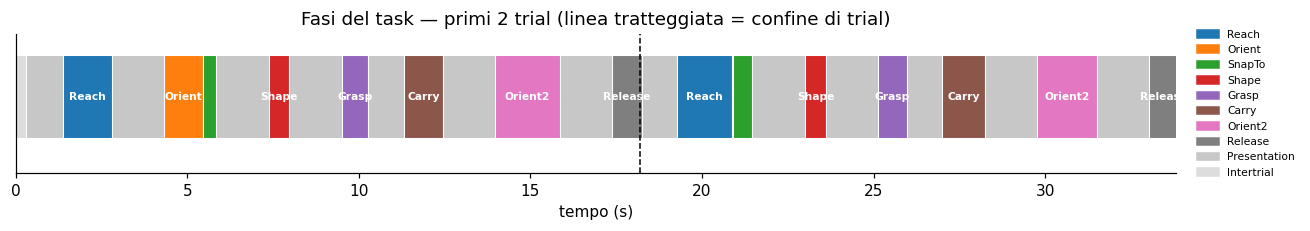

In [4]:
ph_tab = s.epochs.groupby("tag")["dur"].agg(["count", "mean", "min", "max"]).round(2)
ph_tab = ph_tab.reindex([t for t in io.PHASE_COLORS if t in ph_tab.index]
                        + [t for t in ph_tab.index if t not in io.PHASE_COLORS])
display(ph_tab.rename(columns={"count": "n ripetizioni", "mean": "durata media (s)",
                               "min": "min (s)", "max": "max (s)"}))

# timeline delle fasi dei primi 2 trial
a0, b0 = slices[0][0], slices[1][1]
t0, t1 = a0 * io.BIN_S, b0 * io.BIN_S
fig, ax = plt.subplots(figsize=(12, 2.2))
for _, e in s.epochs.iterrows():
    if e.stop_time <= t0 or e.start_time >= t1:
        continue
    base = e.tag.rstrip("234567") if e.tag.startswith("Presentation") else e.tag
    ax.barh(0, e.stop_time - e.start_time, left=e.start_time - t0, height=0.6,
            color=io.PHASE_COLORS.get(base, "0.8"), edgecolor="w", lw=0.7)
    if e.dur > 0.6 and not e.tag.startswith("Presentation"):
        ax.text(e.start_time - t0 + e.dur / 2, 0, e.tag, ha="center", va="center",
                fontsize=7, color="w", fontweight="bold")
ax.axvline((slices[0][1] - a0) * io.BIN_S, color="k", ls="--", lw=1)
ax.set(yticks=[], xlabel="tempo (s)", xlim=(0, t1 - t0), ylim=(-0.55, 0.45),
       title="Fasi del task — primi 2 trial (linea tratteggiata = confine di trial)")
ax.grid(False)
handles = [Patch(color=c, label=t) for t, c in io.PHASE_COLORS.items()]
ax.legend(handles=handles, ncol=1, fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5),
          frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "01_task_phases.png", bbox_inches="tight"); plt.show()


## 4 · Attività neurale — raster + firing rate di popolazione

Raster degli spike di un singolo trial (un punto = uno spike di un'unità) e firing rate mediato
sulle 176 unità. Le bande colorate sullo sfondo sono le fasi del task: si vede che l'attività di
popolazione **si modula in modo sistematico con le fasi**, non è un fondo stazionario.


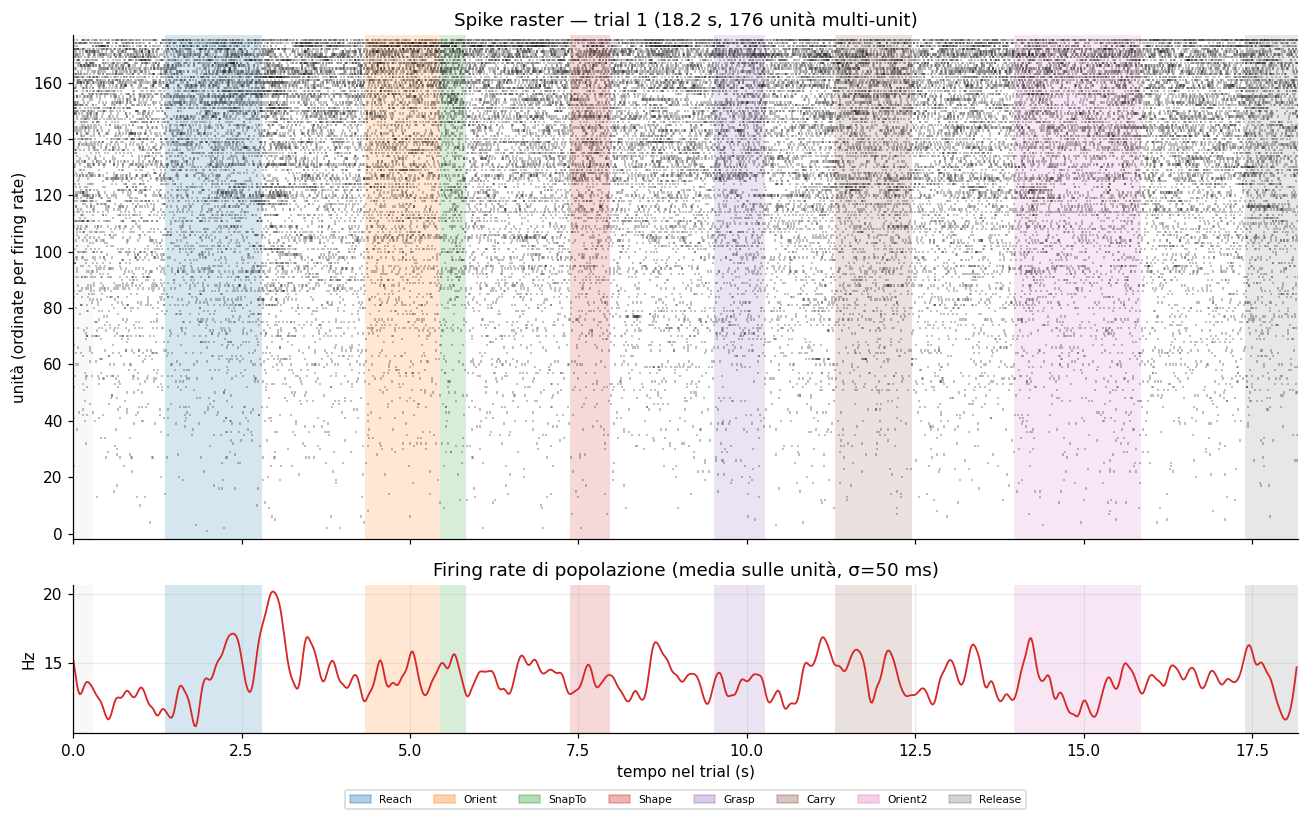

In [5]:
a, b = slices[0]
t0, t1 = a * io.BIN_S, b * io.BIN_S

def shade_phases(ax, alpha=0.18):
    """Sfondo colorato per fase, sull'asse temporale relativo a t0 (trial corrente)."""
    for _, e in s.epochs.iterrows():
        if e.stop_time <= t0 or e.start_time >= t1:
            continue
        base = e.tag.rstrip("234567") if e.tag.startswith("Presentation") else e.tag
        if base == "Presentation":
            continue  # lascio bianche le fasi di sola presentazione del cue
        ax.axvspan(max(e.start_time, t0) - t0, min(e.stop_time, t1) - t0,
                   color=io.PHASE_COLORS.get(base, "0.8"), alpha=alpha, lw=0, zorder=0)

fig, ax = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True,
                       gridspec_kw={"height_ratios": [3.4, 1]})
order = np.argsort(s.spikes.sum(0))          # unità ordinate per attività crescente
events = [s.spike_times[u][(s.spike_times[u] >= t0) & (s.spike_times[u] < t1)] - t0
          for u in order]
ax[0].eventplot(events, colors="k", lineoffsets=np.arange(s.n_units),
                linelengths=0.85, linewidths=0.32)
shade_phases(ax[0])
ax[0].set(ylabel="unità (ordinate per firing rate)", ylim=(-2, s.n_units + 1),
          title=f"Spike raster — trial 1 ({t1-t0:.1f} s, {s.n_units} unità multi-unit)")
ax[0].grid(False)

tt = np.arange(b - a) * io.BIN_S
ax[1].plot(tt, rates[a:b].mean(1), color="C3", lw=1.2)
shade_phases(ax[1])
ax[1].set(xlabel="tempo nel trial (s)", ylabel="Hz", xlim=(0, t1 - t0),
          title="Firing rate di popolazione (media sulle unità, σ=50 ms)")
handles = [Patch(color=io.PHASE_COLORS[t], alpha=0.35, label=t) for t in io.MOVEMENT_PHASES]
ax[1].legend(handles=handles, ncol=8, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.35))
fig.tight_layout(); fig.savefig(FIGS / "01_raster_trial0.png", bbox_inches="tight"); plt.show()


## 5 · La cinematica a 7 DoF (il target)

Le 7 dimensioni della cinematica di riferimento per lo stesso trial: **posizione** (sopra) e
**velocità** (sotto). La velocità è il target ufficiale del benchmark.

Si legge chiaramente la logica del task: durante `Reach` e `Carry` si muovono le traslazioni
(`tx, ty, tz`), durante `Orient`/`Orient2` l'orientamento (`rx`), durante `Shape`/`Grasp`/`Release`
i tre gradi di presa (`g1, g2, g3`). Durante le `Presentation` la cinematica è ferma.


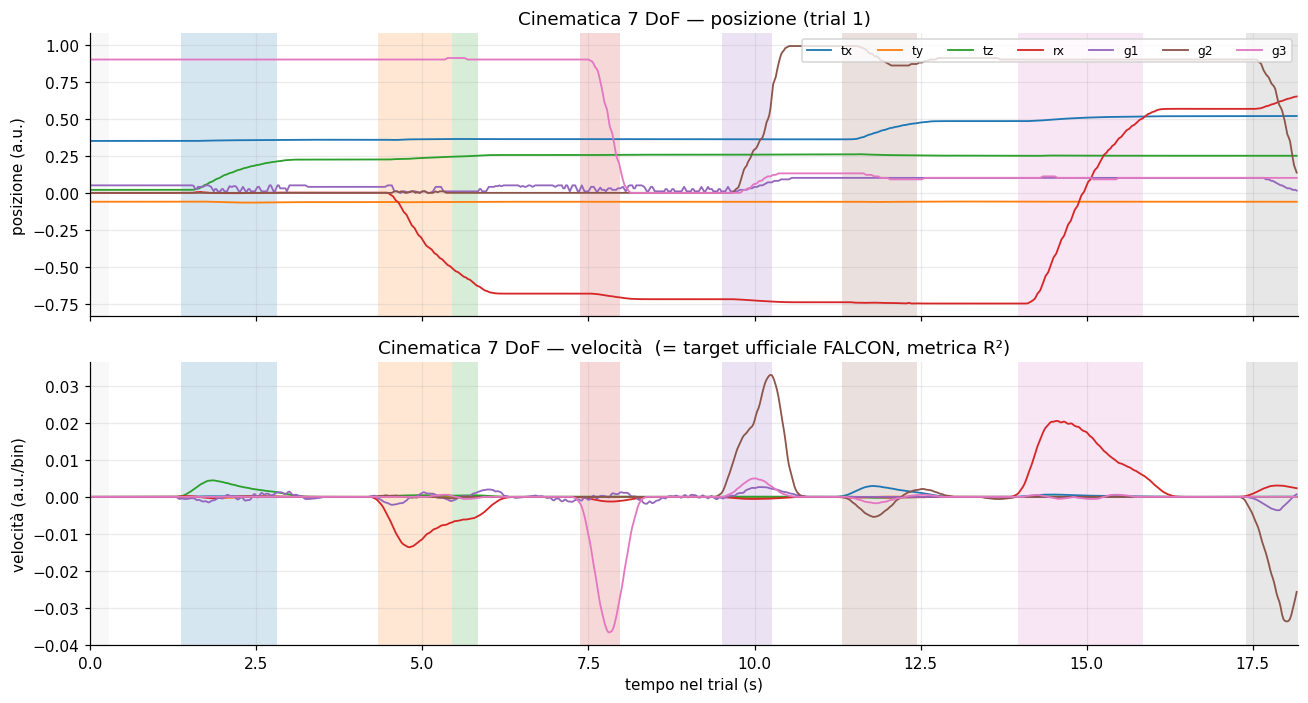

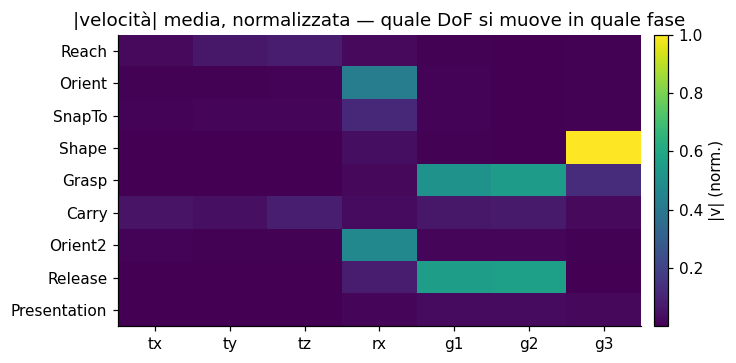

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
cols = plt.cm.tab10(np.linspace(0, 1, 10))
for j, lab in enumerate(io.KIN_LABELS):
    ax[0].plot(tt, s.kin[a:b, j], lw=1.2, color=cols[j], label=lab)
    ax[1].plot(tt, s.vel[a:b, j], lw=1.2, color=cols[j], label=lab)
shade_phases(ax[0]); shade_phases(ax[1])
ax[0].set(ylabel="posizione (a.u.)", title="Cinematica 7 DoF — posizione (trial 1)")
ax[0].legend(ncol=7, fontsize=8, loc="upper right")
ax[1].set(xlabel="tempo nel trial (s)", ylabel="velocità (a.u./bin)", xlim=(0, t1 - t0),
          title="Cinematica 7 DoF — velocità  (= target ufficiale FALCON, metrica R²)")
fig.tight_layout()
# Legenda delle bande di sfondo = fasi del task. Solo le fasi di movimento: le
# `Presentation` non sono ombreggiate (cinematica ferma), quindi non vanno in legenda.
# Va ancorata alla *figura*, non agli assi: tight_layout ignora gli artisti piazzati
# fuori dagli assi e la ritaglierebbe fuori dal canvas. subplots_adjust riserva prima
# il margine in basso, poi fig.legend ci disegna dentro.
fig.subplots_adjust(bottom=0.20)
handles = [Patch(color=io.PHASE_COLORS[t], alpha=0.45, label=t) for t in io.MOVEMENT_PHASES]
fig.legend(handles=handles, ncol=8, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 0.015),
           frameon=False, title="fase del task", title_fontsize=8.5)
fig.savefig(FIGS / "01_kinematics_trial0.png", bbox_inches="tight"); plt.show()

# quale DoF è attivo in quale fase: velocità assoluta media per (fase, DoF)
phase_lab = io.phase_per_bin(s)
mov = pd.DataFrame(np.abs(s.vel), columns=io.KIN_LABELS)
mov["fase"] = [p.rstrip("234567") if p.startswith("Presentation") else p for p in phase_lab]
tab = mov[mov.fase.isin(io.MOVEMENT_PHASES + ("Presentation",))].groupby("fase").mean()
tab = tab.reindex([t for t in io.MOVEMENT_PHASES if t in tab.index] + ["Presentation"])

fig, ax = plt.subplots(figsize=(7, 3.4))
im = ax.imshow(tab.values / tab.values.max(), cmap="viridis", aspect="auto")
ax.set(xticks=range(7), xticklabels=io.KIN_LABELS, yticks=range(len(tab)), yticklabels=tab.index,
       title="|velocità| media, normalizzata — quale DoF si muove in quale fase")
fig.colorbar(im, ax=ax, label="|v| (norm.)", pad=0.02)
ax.grid(False)
fig.tight_layout(); fig.savefig(FIGS / "01_phase_dof_map.png", bbox_inches="tight"); plt.show()


## 6 · Il problema di decoding in una figura

Attività neurale delle 176 unità (sopra) ↔ velocità dei 7 DoF (sotto), stesso asse temporale.
Questo è **esattamente** ciò che la pipeline dovrà imparare: *manifold neurale → cinematica*.
Rispetto a B1 (neurale → spettrogramma → audio) il target è molto più a bassa dimensione,
ma il problema resta lo stesso: estrarre da 176 canali rumorosi le poche dimensioni latenti
che portano il segnale comportamentale.


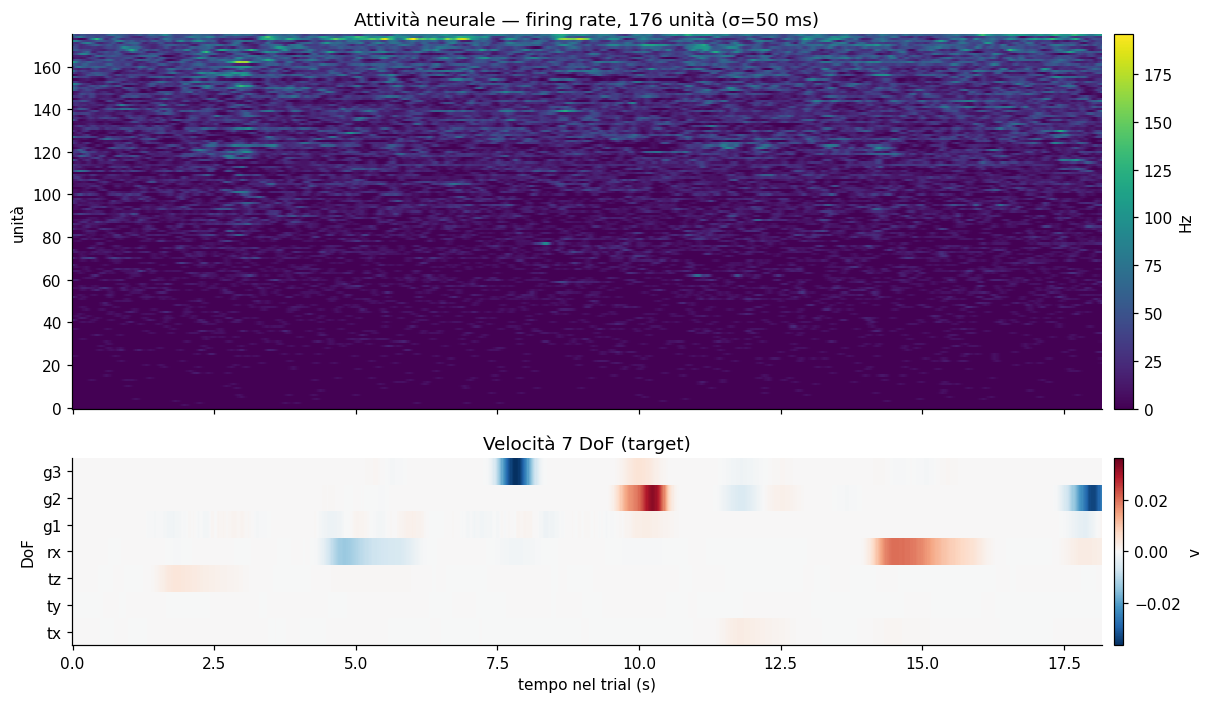

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True,
                       gridspec_kw={"height_ratios": [2, 1]})
im0 = ax[0].pcolormesh(tt, np.arange(s.n_units), rates[a:b][:, order].T,
                       shading="auto", cmap="viridis")
ax[0].set(ylabel="unità", title="Attività neurale — firing rate, 176 unità (σ=50 ms)")
fig.colorbar(im0, ax=ax[0], label="Hz", pad=0.01)
ax[0].grid(False)
im1 = ax[1].pcolormesh(tt, np.arange(7), s.vel[a:b].T, shading="auto", cmap="RdBu_r",
                       vmin=-np.abs(s.vel[a:b]).max(), vmax=np.abs(s.vel[a:b]).max())
ax[1].set(xlabel="tempo nel trial (s)", yticks=range(7), yticklabels=io.KIN_LABELS,
          ylabel="DoF", title="Velocità 7 DoF (target)")
fig.colorbar(im1, ax=ax[1], label="v", pad=0.01)
ax[1].grid(False)
fig.tight_layout(); fig.savefig(FIGS / "01_neural_vs_kinematics.png", bbox_inches="tight"); plt.show()


## 7 · L'attività neurale è davvero modulata dal task?

Prima di costruire qualunque modello conviene verificare che il segnale ci sia. Calcoliamo il
**PSTH di popolazione allineato all'inizio di ogni fase** (media su tutte le ripetizioni della
fase nella sessione): se la corteccia motoria codifica il movimento tentato, il firing rate deve
aumentare in modo *fase-specifico* dopo l'onset.

Aggiungiamo anche una misura per-unità: la **modulazione tra fasi**, cioè quanto il firing rate
medio di ciascuna unità varia da una fase all'altra rispetto alla sua variabilità interna
(un'ANOVA a una via, riportata come frazione di varianza spiegata dalla fase, η²).


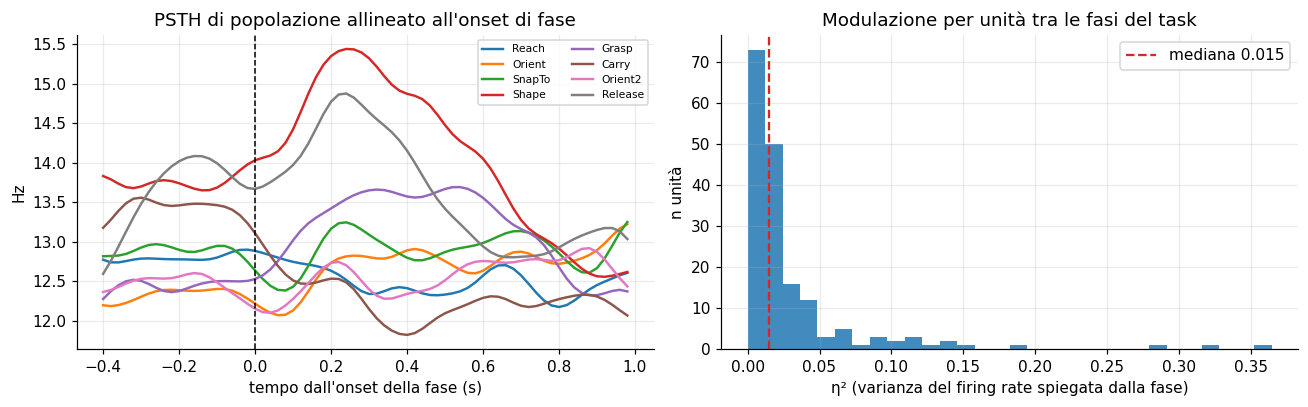

η² mediano: 0.015   massimo: 0.364
Unità con η² > 0.05: 25/176  (> 0.10: 13)


In [8]:
# PSTH di popolazione allineato all'onset di ogni fase di movimento
PRE, POST = 0.4, 1.0
npre, npost = int(PRE / io.BIN_S), int(POST / io.BIN_S)
pop = rates.mean(1)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for tag in io.MOVEMENT_PHASES:
    onsets = [int(round(e.start_time / io.BIN_S)) for _, e in s.epochs.iterrows() if e.tag == tag]
    segs = [pop[o - npre:o + npost] for o in onsets if o - npre >= 0 and o + npost <= s.n_bins]
    if not segs:
        continue
    m = np.mean(segs, 0)
    ax[0].plot(np.arange(-npre, npost) * io.BIN_S, m, color=io.PHASE_COLORS[tag], lw=1.6, label=tag)
ax[0].axvline(0, color="k", ls="--", lw=1)
ax[0].set(xlabel="tempo dall'onset della fase (s)", ylabel="Hz",
          title="PSTH di popolazione allineato all'onset di fase")
ax[0].legend(fontsize=7, ncol=2)

# modulazione per unità: eta^2 dell'ANOVA firing rate ~ fase
lab = np.array([p.rstrip("234567") if p.startswith("Presentation") else p for p in phase_lab])
keep = np.isin(lab, io.MOVEMENT_PHASES + ("Presentation",))
X, L = rates[keep], lab[keep]
gm = X.mean(0)
ss_tot = ((X - gm) ** 2).sum(0)
ss_between = np.zeros(s.n_units)
for g in np.unique(L):
    m = L == g
    ss_between += m.sum() * (X[m].mean(0) - gm) ** 2
eta2 = ss_between / np.maximum(ss_tot, 1e-12)
ax[1].hist(eta2, bins=30, color="C0", alpha=0.85)
ax[1].axvline(np.median(eta2), color="C3", ls="--", label=f"mediana {np.median(eta2):.3f}")
ax[1].set(xlabel="η² (varianza del firing rate spiegata dalla fase)", ylabel="n unità",
          title="Modulazione per unità tra le fasi del task")
ax[1].legend()
fig.tight_layout(); fig.savefig(FIGS / "01_task_modulation.png", bbox_inches="tight"); plt.show()
print(f"η² mediano: {np.median(eta2):.3f}   massimo: {eta2.max():.3f}")
print(f"Unità con η² > 0.05: {(eta2 > 0.05).sum()}/{s.n_units}  "
      f"(> 0.10: {(eta2 > 0.10).sum()})")


**Interpretazione — ed è un risultato importante per il seguito.** Il PSTH di popolazione mostra
modulazioni **fase-specifiche** chiare (le fasi di manipolazione della mano — `Shape`, `Release`,
`Grasp` — producono i picchi maggiori), ma l'istogramma a destra dice che **la singola unità porta
poca informazione**: η² mediano ≈ 0.015, e solo ~25 unità su 176 superano 0.05.

Questo è il quadro tipico dei segnali multi-unit corticali: il codice motorio è **distribuito
sulla popolazione**, non leggibile da singoli canali. È esattamente la premessa che giustifica
l'approccio della tesi — cercare le poche **dimensioni latenti condivise** (il *neural manifold*)
in cui il segnale comportamentale emerge, invece di trattare le 176 unità come feature indipendenti.
Il notebook 02 parte da qui.


## 8 · `eval_mask`: cosa viene effettivamente valutato

Il benchmark esclude alcuni bin dalla metrica. Vediamo **quali**, perché è un dettaglio che
cambia i risultati se ignorato.


In [9]:
ev = pd.DataFrame({"fase": lab if len(lab) == s.n_bins else phase_lab, "eval": s.eval_mask})
ev["fase"] = [p.rstrip("234567") if p.startswith("Presentation") else p for p in ev["fase"]]
frac = ev.groupby("fase")["eval"].agg(["mean", "size"]).sort_values("mean")
display(frac.rename(columns={"mean": "frazione bin valutati", "size": "n bin"}).round(3))
print(f"Bin esclusi in totale: {(~s.eval_mask).sum()} / {s.n_bins} "
      f"({100*(1-s.eval_mask.mean()):.1f}%)")


,frazione bin valutati,n bin
fase,,
SnapTo,0.003,291
Intertrial,0.717,53
Presentation,1.000,6672
,1.000,1
Carry,1.000,971
Grasp,1.000,621
Orient,1.000,757
Orient2,1.000,854
Reach,1.000,958


Bin esclusi in totale: 307 / 12233 (2.5%)


**Interpretazione.** Le esclusioni si concentrano quasi interamente sulla fase **`SnapTo`** (e in
parte su `Intertrial`). Ha senso: `SnapTo` è il momento in cui il braccio virtuale **scatta
automaticamente** nella posa corretta — è una correzione imposta dal software, non un movimento
che il partecipante sta tentando. Valutare il decoder lì significherebbe chiedergli di predire
un artefatto della simulazione. Lo stesso vale per le pause tra trial.

**Conseguenza pratica:** `eval_mask` va applicata al calcolo dell'R², e conviene escludere quei
bin anche in fase di training per non insegnare al modello una relazione neurale↔cinematica
che nel task non esiste.


## 9 · Statistiche di base


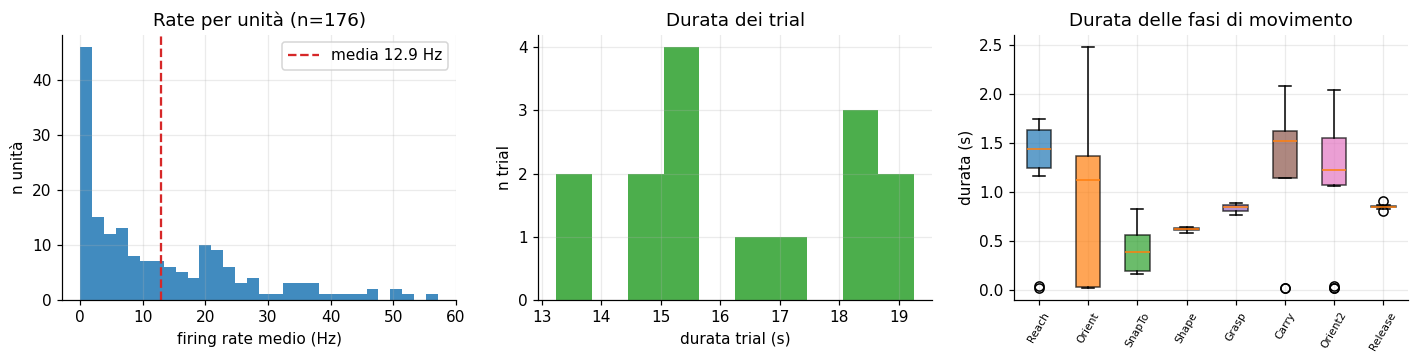

Unità quasi silenti (<0.5 Hz): 16/176 → escluse dalle analisi di manifold.
Unità più attive (Hz): [57.2 51.7 51.2 50.6 47.2]


In [10]:
unit_hz = s.spikes.sum(0) / s.duration_s
all_phase_dur = s.epochs[s.epochs.tag.isin(io.MOVEMENT_PHASES)]

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(unit_hz, bins=30, color="C0", alpha=0.85)
ax[0].axvline(unit_hz.mean(), color="C3", ls="--", label=f"media {unit_hz.mean():.1f} Hz")
ax[0].set(xlabel="firing rate medio (Hz)", ylabel="n unità",
          title=f"Rate per unità (n={s.n_units})")
ax[0].legend()

ax[1].hist(durs, bins=10, color="C2", alpha=0.85)
ax[1].set(xlabel="durata trial (s)", ylabel="n trial", title="Durata dei trial")

data = [all_phase_dur[all_phase_dur.tag == t].dur.values for t in io.MOVEMENT_PHASES]
bp = ax[2].boxplot(data, tick_labels=list(io.MOVEMENT_PHASES), patch_artist=True)
for patch, t in zip(bp["boxes"], io.MOVEMENT_PHASES):
    patch.set_facecolor(io.PHASE_COLORS[t]); patch.set_alpha(0.7)
ax[2].tick_params(axis="x", rotation=60, labelsize=7)
ax[2].set(ylabel="durata (s)", title="Durata delle fasi di movimento")
fig.tight_layout(); fig.savefig(FIGS / "01_stats.png", bbox_inches="tight"); plt.show()

n_silent = int((unit_hz < 0.5).sum())
print(f"Unità quasi silenti (<0.5 Hz): {n_silent}/{s.n_units} → escluse dalle analisi di manifold.")
print("Unità più attive (Hz):", np.round(np.sort(unit_hz)[::-1][:5], 1))


## 10 · Sintesi e prossimi passi

**Cosa abbiamo stabilito.**

1. **Feature neurale** = conteggi di spike di 176 unità multi-unit, binnati a **20 ms** (passo
   nativo del benchmark). I firing rate si ottengono con smoothing gaussiano σ = 50 ms.
   ~16 unità sono quasi silenti (<0.5 Hz) e verranno escluse dal manifold learning.
2. **Target** = cinematica 7 DoF; la metrica ufficiale è l'**R² sulla velocità**, già allineata
   bin per bin all'attività neurale (nessun problema di sincronizzazione da risolvere).
3. **Struttura del task**: ogni trial è una sequenza di **fasi stereotipate e ripetute**
   (Reach, Orient, SnapTo, Shape, Grasp, Carry, Orient2, Release), con ~15 ripetizioni per
   sessione e 170 sull'intero split held-in. Sono **condizioni discrete**, cosa che B1 non aveva.
4. **Il segnale c'è, ma è distribuito**: il firing rate di *popolazione* si modula in modo
   fase-specifico, mentre la singola unità spiega poca varianza (η² mediano ≈ 0.015, 25/176 unità
   sopra 0.05). È la motivazione diretta per l'analisi a livello di popolazione (manifold).
5. **`eval_mask`** esclude soprattutto la fase `SnapTo` (movimento imposto dal software, non
   tentato dal partecipante): va rispettata sia in valutazione sia in training.
6. **Gli split** sono già pronti per l'esperimento chiave del benchmark: held-in per il training,
   held-out (sessioni di giorni successivi, 3 trial ciascuna) per la **few-shot recalibration**.

**Prossimo passo — `02_baseline_manifolds.ipynb`:** estrazione del manifold neurale con i due
metodi lineari classici, **PCA** e **GPFA**, selezione della dimensionalità latente, e confronto
quantitativo su lisciezza e consistenza single-trial. Le fasi del task saranno usate come
condizioni per colorare e allineare le traiettorie latenti.
